# Proyecto Oráculo · Notebook de búsqueda · Grupo G01

**Análisis y Diseño de Algoritmos · Universidad de Caldas · 2026-2**
Integrante: Jackeline Rivera Aguilera · Semana de entrega: 4

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/J2517/ADA-2026-2-GP01/blob/main/busqueda_G01.ipynb)

Este notebook documenta cómo se obtuvo la configuración de `entrega.json`: método, parámetros,
todas las configuraciones evaluadas con su precisión, uso de las trazas de fallos para podar
opciones y validación final con `oraculo.validar`.

| Fase | Qué hace | Evaluaciones (100 instancias c/u) |
|---|---|---|
| 0 · Base | Prompt sin instrucciones | 1 |
| 1 · Cribado guiado por trazas | Cada opción sola; se miden las instancias que rompe y qué familia falló → poda | 5 × 8 = 40 |
| 2 · Ascenso por coordenadas | Sobre las 3 opciones que sobreviven por ranura | ≤ 10 por pasada |
| 3 · Verificación del vecindario | Una pasada con las 8 opciones → certifica óptimo local | ≤ 35 |
| 4 · Temperatura | 0.3 y 0.7 con 3 semillas cada una | 6 |

Total esperado: ≈ 80–100 evaluaciones, frente a las 32 768 de la fuerza bruta.
El resultado es la mejor configuración encontrada y un óptimo local (ningún cambio de una sola
ranura la mejora); no es una garantía de óptimo global (el problema es NP-difícil, ver informe).

**Cómo correrlo:** Entorno de ejecución ▸ Cambiar tipo ▸ T4 GPU → celda 1 → reiniciar sesión → resto en orden.
El caché vive en Google Drive: si Colab se desconecta, volver a correr las celdas reutiliza lo ya generado.

## 1 · Instalar y bajar los archivos del repositorio  ·  *al terminar, reinicia la sesión*

In [1]:
!pip install -q -U "bitsandbytes>=0.46.1" transformers accelerate \
                   nltk spacy emoji langdetect immutabledict
!python -m spacy download en_core_web_sm -q
!git clone -q https://github.com/allenai/open-instruct

# Versión fija del grupo (fork). --no-cache para no reusar archivos viejos.
REPO = "https://raw.githubusercontent.com/J2517/ADA-2026-2-GP01/main"
for f in ["oraculo.py", "ayudas.py", "datos_visibles.json", "registro.py", "busqueda.py"]:
    !wget -q --no-cache -O {f} {REPO}/{f}

# Datos de nltk a mano (el downloader rechaza el proxy de Colab).
import io, urllib.request, zipfile
NLTK_DATA = "https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages"
for carpeta, nombre in [("tokenizers", "punkt"), ("tokenizers", "punkt_tab"),
                        ("taggers", "averaged_perceptron_tagger"),
                        ("taggers", "averaged_perceptron_tagger_eng")]:
    with urllib.request.urlopen(f"{NLTK_DATA}/{carpeta}/{nombre}.zip") as resp:
        zipfile.ZipFile(io.BytesIO(resp.read())).extractall(f"/root/nltk_data/{carpeta}")

print("LISTO  →  Entorno de ejecución ▸ Reiniciar sesión, y sigue en la celda 2")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
LISTO  →  Entorno de ejecución ▸ Reiniciar sesión, y sigue en la celda 2


## 2 · El modelo
Qwen3-1.7B en fp16. Requiere GPU T4.

In [1]:
from ayudas import cargar_modelo
modelo = cargar_modelo("qwen17b")

cargando qwen17b → Qwen/Qwen3-1.7B


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Qwen/Qwen3-1.7B  VRAM: 3.44 GB


## 3 · El oráculo, los datos y el registro

- Se busca solo sobre `busqueda` (100 instancias), siempre las mismas y con `semilla=1`,
  para que todas las configuraciones se comparen en igualdad de condiciones (pasos de 1 %).
- `Registro` (en `registro.py`) envuelve al oráculo: anota cada configuración evaluada con su
  precisión, consultas, generaciones nuevas, tiempo y familias violadas.
- `consultas` = costo lógico (instancias consultadas, el presupuesto B del informe).
  `generaciones` = las que de verdad corrieron en GPU en esta sesión (las demás salieron del caché).

In [2]:
import os
USAR_DRIVE = True   # recomendado: el caché sobrevive a desconexiones

if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    CARPETA = "/content/drive/MyDrive/oraculo_G01"
else:
    CARPETA = "/content/resultados_G01"
os.makedirs(CARPETA, exist_ok=True)

from oraculo import Oraculo, CATALOGO, espacio
from ayudas import cargar_datos, dividir
from registro import Registro, RANURAS, config_completa
from busqueda import (cribado, podar, inicio_desde_cribado, ascenso,
                      todas_las_opciones, probar_temperaturas)

datos = cargar_datos()
busqueda, validacion = dividir(datos)
oraculo = Oraculo(modelo, busqueda, validacion, cache=f"{CARPETA}/cache_oraculo.json",
                  lote=16, presupuesto=32_000_000)

CONFIGS = espacio()
INSTANCIAS = busqueda
K = len(CATALOGO["rol"])
print(len(CONFIGS), "configuraciones posibles ·", len(INSTANCIAS), "instancias de búsqueda · k =", K)

reg = Registro(oraculo, INSTANCIAS, semilla=1)

Mounted at /content/drive
450 instancias, 2.3 restricciones por instancia
búsqueda: 100 inst, 2.5 restr/inst
validación: 87 inst, 2.4 restr/inst
(263 instancias descartadas: no medían nada — ver `dividir`)
modo pensamiento: apagado
caché: 9048 respuestas recuperadas
32768 configuraciones posibles · 100 instancias de búsqueda · k = 8


## 4 · Búsqueda

### Fase 0 · Línea base y estimación de tiempo
La base es el prompt sin ninguna instrucción (el oráculo permite configuraciones parciales:
una ranura ausente no pega texto). Sirve de referencia para medir qué rompe y qué arregla cada opción.

In [3]:
base_cfg = {"temperatura": 0.0}
r_base = reg.evaluar(base_cfg, "0-base", "sin instrucciones")
seg = reg.filas[-1]["segundos"]
if reg.filas[-1]["generaciones"]:
    print(f"\nUna evaluación de {len(INSTANCIAS)} instancias tardó {seg/60:.1f} min.")
    print(f"Estimado del cribado (40 evaluaciones): ~{40*seg/3600:.1f} h  "
          "(las opciones que alargan la respuesta tardan más).")

[  1] 0-base       (sin instrucciones) T=0.0          precisión  16.0%   gen nuevas    0      0.0s  sin instrucciones


### Fase 1 · Cribado por ranura guiado por trazas
Cada una de las 40 opciones se evalúa sola (las otras cuatro ranuras vacías). Contra la base:

- **roturas**: instancias que la base acertaba y que con esta opción fallan, con la familia de
  restricción que falló según las trazas (`violo`);
- **arreglos**: instancias que la base fallaba y que con esta opción aciertan.

Idea: cada ranura afecta una parte distinta de la respuesta (inicio, largo, estructura, caracteres,
final). Si una opción rompe sistemáticamente familias de esa parte (p. ej. `first_word` para una
opción de `rol` que obliga a empezar con una frase fija), es dañina y se poda.

In [4]:
r_base, tabla = cribado(reg, K)

[  2] 1-cribado    rol=0 T=0.0                        precisión  15.0%   gen nuevas    0      0.0s  
[  3] 1-cribado    rol=1 T=0.0                        precisión  16.0%   gen nuevas    0      0.0s  
[  4] 1-cribado    rol=2 T=0.0                        precisión  18.0%   gen nuevas    0      0.0s  
[  5] 1-cribado    rol=3 T=0.0                        precisión  18.0%   gen nuevas    0      0.0s  
[  6] 1-cribado    rol=4 T=0.0                        precisión  11.0%   gen nuevas    0      0.0s  
[  7] 1-cribado    rol=5 T=0.0                        precisión  14.0%   gen nuevas    0      0.0s  
[  8] 1-cribado    rol=6 T=0.0                        precisión  15.0%   gen nuevas    0      0.0s  
[  9] 1-cribado    rol=7 T=0.0                        precisión  13.0%   gen nuevas    0      0.0s  
[ 10] 1-cribado    est=0 T=0.0                        precisión  12.0%   gen nuevas    0      0.0s  
[ 11] 1-cribado    est=1 T=0.0                        precisión  11.0%   gen nuevas    0   

In [5]:
import pandas as pd
pd.set_option("display.max_colwidth", 90)

df_crib = pd.DataFrame([{k: v for k, v in f.items() if k not in ("familias_rotas", "ids_rotas")}
                        for f in tabla])
print(f"Base sin instrucciones: {r_base.precision:.1%}\n")
print("Precisión de cada opción sola (filas = ranura, columnas = índice de opción):")
display(df_crib.pivot(index="ranura", columns="opcion", values="precision")
        .loc[RANURAS].style.format("{:.0%}").background_gradient(axis=1, cmap="RdYlGn"))
print("Roturas (instancias que la base acertaba y esta opción tumba):")
display(df_crib.pivot(index="ranura", columns="opcion", values="roturas").loc[RANURAS])

Base sin instrucciones: 16.0%

Precisión de cada opción sola (filas = ranura, columnas = índice de opción):


opcion,0,1,2,3,4,5,6,7
ranura,,,,,,,,
rol,15%,16%,18%,18%,11%,14%,15%,13%
estrategia,12%,11%,16%,15%,12%,10%,19%,15%
formato,18%,8%,11%,11%,9%,6%,12%,7%
estilo,19%,15%,17%,16%,11%,15%,16%,18%
cierre,12%,11%,10%,18%,10%,11%,11%,7%


Roturas (instancias que la base acertaba y esta opción tumba):


opcion,0,1,2,3,4,5,6,7
ranura,,,,,,,,
rol,7,7,6,5,8,5,8,8
estrategia,8,9,7,9,7,8,2,9
formato,7,10,9,7,10,11,7,13
estilo,4,6,8,7,10,7,6,6
cierre,9,9,10,6,8,8,8,11


#### Lectura de trazas por ranura
Para cada opción: su precisión, cuántas instancias rompe, qué familias rompe y un fragmento de
una salida rota (el texto real que generó el modelo). Esta es la evidencia de la poda.

In [6]:
def ver_roturas(ranura, ejemplos=1, largo=220):
    print(f"══════════ {ranura.upper()} ══════════")
    filas = sorted([f for f in tabla if f["ranura"] == ranura],
                   key=lambda f: (-f["precision"], f["roturas"]))
    for f in filas:
        fams = ", ".join(f"{a} ×{b}" for a, b in f["familias_rotas"].most_common(3)) or "—"
        print(f"\n[{ranura} {f['opcion']}] {f['precision']:.0%} (Δ {f['delta']:+.0%}) · "
              f"roturas {f['roturas']} · arreglos {f['arreglos']}")
        print(f"   texto : {CATALOGO[ranura][f['opcion']][:110]}")
        print(f"   rompe : {fams}")
        r = reg.resultado({ranura: f["opcion"], "temperatura": 0.0})
        for iid in f["ids_rotas"][:ejemplos]:
            salida = next(t["salida"] for t in r.trazas if t["id"] == iid)
            print(f"   ej. id {iid} ({r.fallidas[iid]}): {salida[:largo]!r}")

for ranura in RANURAS:
    ver_roturas(ranura)
    print()

══════════ ROL ══════════

[rol 3] 18% (Δ +2%) · roturas 5 · arreglos 7
   texto : You are a structured assistant. Start every reply with the line "Answer:" before the answer itself.
   rompe : copy:copy ×1, change_case:english_capital ×1, length_constraints:number_words ×1
   ej. id 386 (copy:copy): 'Answer: The library received a 25% increase in its annual funding. With the original budget, they could purchase 12 bookshelves for $80 each if they allocated the entire budget for that purpose. The new budget is 25% mor'

[rol 2] 18% (Δ +2%) · roturas 6 · arreglos 8
   texto : You are a thorough assistant. Open every reply by restating the question in your own words, then answer.
   rompe : copy:copy ×1, length_constraints:number_words ×1, change_case:english_capital ×1
   ej. id 386 (copy:copy): 'The library received a 25% increase in its annual funding. With the original budget, they could purchase 12 bookshelves for $80 each if they allocated the entire budget for that purpose. If the

#### Poda
**Criterio:** en cada ranura se ordenan las opciones por precisión (y, en empate, por menos roturas) y se
conservan las 3 mejores; las otras 5 se descartan, dejando escrito qué familias rompían.
Para no confiar ciegamente en esta poda, la Fase 3 vuelve a probar las 8 opciones en contexto.

In [7]:
CONSERVAR = 3
candidatos, descartes = podar(tabla, conservar=CONSERVAR)
print("Sobreviven:", candidatos)
print(f"Espacio tras la poda: {CONSERVAR}^5 = {CONSERVAR**5} configs (antes {K**5})\n")
display(pd.DataFrame(descartes))

Sobreviven: {'rol': [3, 2, 1], 'estrategia': [6, 2, 3], 'formato': [0, 6, 3], 'estilo': [0, 7, 2], 'cierre': [3, 0, 5]}
Espacio tras la poda: 3^5 = 243 configs (antes 32768)



,ranura,opcion,precision,roturas,motivo
0,rol,0,0.15,7,"copy:copy x1, last_word:last_word_answer x1, change_case:english_capital x1"
1,rol,6,0.15,8,"keywords:word_count_different_numbers x2, copy:copy x1, last_word:last_word_answer x1"
2,rol,5,0.14,5,"last_word:last_word_answer x1, keywords:word_once x1, keywords:frequency x1"
3,rol,7,0.13,8,"change_case:english_lowercase x2, keywords:word_count_different_numbers x2, copy:copy x1"
4,rol,4,0.11,8,"length_constraints:number_words x2, copy:copy x1, change_case:english_capital x1"
5,estrategia,7,0.15,9,"last_word:last_word_answer x2, keywords:word_once x1, keywords:word_count_different_nu..."
6,estrategia,4,0.12,7,"last_word:last_word_answer x2, copy:copy x1, change_case:english_capital x1"
7,estrategia,0,0.12,8,"copy:copy x1, last_word:last_word_answer x1, keywords:word_once x1"
8,estrategia,1,0.11,9,"last_word:last_word_answer x2, keywords:frequency x2, copy:copy x1"
9,estrategia,5,0.10,8,"copy:copy x1, last_word:last_word_answer x1, length_constraints:number_words x1"


### Interpretación de las trazas del cribado

> Nota de lectura: en la salida impresa del cribado, la etiqueta `est=` de las filas 2–17 es estrategia y la de las filas 26–33 es estilo (las dos ranuras empiezan igual).

**1. Las opciones que imponen una forma literal rompen la familia de la superficie que tocan.**
- `rol` 0, 7, 4 y 3 pegan un prefijo fijo (*"Happy to help!"*, *"Sure thing!"*, *"Topic:"*, *"Answer:"*): se ve en las salidas de ejemplo.
- `formato 1` (documento markdown con viñetas) rompe `detectable_format:number_bullet_lists` (×3).
- `estilo 4` (todo en minúsculas) rompe `change_case:english_capital` (×2).
- Los cierres que agregan una línea final — `cierre 0` (*"Hope this helps…"*), `4` (P.S.), `5` (pregunta) y `7` (*"Next:"*) — rompen sobre todo `last_word:last_word_answer` (×2–3): la última palabra deja de ser la pedida.

**2. Varias opciones hacen que el modelo copie la instrucción dentro de su respuesta.** Con `formato 5`, `formato 7`, `estilo 1`, `estilo 5` y `cierre 2`, la salida empieza repitiendo el texto del catálogo (p. ej. *"Number every paragraph of your reply…"*). Eso rompe restricciones de copia y de primera palabra, y explica que `formato 5` (6 %) y `formato 7` (7 %) sean las peores de todo el cribado.

**3. El recordatorio de restricciones es la única opción de `cierre` que ayuda.** `cierre 3` llega a 18 % con 8 arreglos; las otras siete quedan entre 7 % y 12 %.

**4. Hay instancias frágiles que casi cualquier instrucción tumba.** La 386 (`copy:copy`, copiar un texto literal) y la 483 (`last_word:last_word_answer`) aparecen en las roturas de casi todas las opciones. Por eso la mayoría de familias rotas aparecen solo ×1–2 y el conteo de roturas separa menos de lo esperado.

**5. Las diferencias pequeñas no son concluyentes.** Con 100 instancias y precisiones cercanas al 16 %, el error estándar es ≈ ±3,7 puntos. Muchas opciones difieren de la base en 1–3 puntos. Decisión derivada: no quedarse con una sola opción por ranura sino con **3**, y verificar después las 8 en contexto (Fase 3).

**Decisiones tomadas con esta evidencia:** se descartaron 25 de las 40 opciones (tabla de poda). Las más claras: `formato` 1, 4, 5 y 7, `estilo` 4, `cierre` 2, 4 y 7, y `rol` 4 y 7. El espacio pasó de 32 768 a 243 configuraciones para la Fase 2.

### Fase 2 · Ascenso por coordenadas sobre las opciones que sobrevivieron
- **Inicio:** la mejor opción de cada ranura en el cribado.
- **Paso:** para cada ranura, en orden `rol → estrategia → formato → estilo → cierre`, se prueban sus
  candidatos con las otras 4 fijas; se cambia solo si la precisión mejora estrictamente.
- **Parada:** una pasada completa sin mejoras (convergencia) o 3 pasadas.

In [8]:
inicio = inicio_desde_cribado(tabla)
print("Inicio:", inicio)
cfg2, p2, pasadas2, conv2 = ascenso(reg, inicio, candidatos, fase="2-ascenso", max_pasadas=3)
print(f"\nFase 2 → {cfg2}  precisión {p2:.1%}  ({pasadas2} pasadas, convergió={conv2})")

Inicio: {'rol': 3, 'estrategia': 6, 'formato': 0, 'estilo': 0, 'cierre': 3, 'temperatura': 0.0}
[ 42] 2-ascenso    rol=3 est=6 for=0 est=0 cie=3 T=0.0 precisión  15.0%   gen nuevas    0      0.0s  inicio
[ 43] 2-ascenso    rol=2 est=6 for=0 est=0 cie=3 T=0.0 precisión  13.0%   gen nuevas    0      0.0s  pasada 1, rol
[ 44] 2-ascenso    rol=1 est=6 for=0 est=0 cie=3 T=0.0 precisión  16.0%   gen nuevas    0      0.0s  pasada 1, rol
      ↑ rol: 3 → 1  (15.0% → 16.0%)
[ 45] 2-ascenso    rol=1 est=2 for=0 est=0 cie=3 T=0.0 precisión  18.0%   gen nuevas    0      0.0s  pasada 1, estrategia
[ 46] 2-ascenso    rol=1 est=3 for=0 est=0 cie=3 T=0.0 precisión  14.0%   gen nuevas    0      0.0s  pasada 1, estrategia
      ↑ estrategia: 6 → 2  (16.0% → 18.0%)
[ 47] 2-ascenso    rol=1 est=2 for=6 est=0 cie=3 T=0.0 precisión  13.0%   gen nuevas    0      0.0s  pasada 1, formato
[ 48] 2-ascenso    rol=1 est=2 for=3 est=0 cie=3 T=0.0 precisión  17.0%   gen nuevas    0      0.0s  pasada 1, formato
[ 49]

### Fase 3 · Verificación del vecindario completo
El mismo ascenso, pero ahora con las 8 opciones de cada ranura, partiendo de la config de la Fase 2.
Si una pasada completa no mejora nada, la configuración es un óptimo local 1-opt: ninguna
configuración que difiera en una sola ranura la supera. Si algo mejora, la poda de la Fase 1 se
equivocó en contexto (interacción entre ranuras) y el ascenso sigue desde ahí.

In [9]:
cfg3, p3, pasadas3, conv3 = ascenso(reg, cfg2, todas_las_opciones(K),
                                    fase="3-verificacion", max_pasadas=3)
print(f"\nFase 3 → {cfg3}  precisión {p3:.1%}  ({pasadas3} pasadas, convergió={conv3})")
print("La poda de la Fase 1 se sostuvo." if cfg3 == cfg2 else
      "La verificación encontró una mejora que la poda había descartado.")

[ 59] 3-verificacion rol=0 est=2 for=0 est=7 cie=3 T=0.0 precisión   9.0%   gen nuevas    0      0.0s  pasada 1, rol
[ 60] 3-verificacion rol=4 est=2 for=0 est=7 cie=3 T=0.0 precisión  16.0%   gen nuevas    0      0.0s  pasada 1, rol
[ 61] 3-verificacion rol=5 est=2 for=0 est=7 cie=3 T=0.0 precisión  11.0%   gen nuevas    0      0.0s  pasada 1, rol
[ 62] 3-verificacion rol=6 est=2 for=0 est=7 cie=3 T=0.0 precisión  20.0%   gen nuevas    0      0.0s  pasada 1, rol
[ 63] 3-verificacion rol=7 est=2 for=0 est=7 cie=3 T=0.0 precisión  11.0%   gen nuevas    0      0.0s  pasada 1, rol
      ↑ rol: 1 → 6  (19.0% → 20.0%)
[ 64] 3-verificacion rol=6 est=0 for=0 est=7 cie=3 T=0.0 precisión  16.0%   gen nuevas    0      0.0s  pasada 1, estrategia
[ 65] 3-verificacion rol=6 est=1 for=0 est=7 cie=3 T=0.0 precisión  12.0%   gen nuevas    0      0.0s  pasada 1, estrategia
[ 66] 3-verificacion rol=6 est=3 for=0 est=7 cie=3 T=0.0 precisión  16.0%   gen nuevas    0      0.0s  pasada 1, estrategia
[ 67] 3

evaluando:   0%|          | 0/52 [00:00<?, ?inst/s]

[ 91] 3-verificacion rol=6 est=6 for=0 est=7 cie=7 T=0.0 precisión   9.0%   gen nuevas   52    133.9s  pasada 1, cierre


evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

[ 92] 3-verificacion rol=0 est=6 for=0 est=7 cie=3 T=0.0 precisión  15.0%   gen nuevas  100    212.6s  pasada 2, rol


...

[ 95] 3-verificacion rol=4 est=6 for=0 est=7 cie=3 T=0.0 precisión  13.0%   gen nuevas  100    211.6s  pasada 2, rol


evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

[ 96] 3-verificacion rol=5 est=6 for=0 est=7 cie=3 T=0.0 precisión  14.0%   gen nuevas  100    211.7s  pasada 2, rol


evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

[ 97] 3-verificacion rol=7 est=6 for=0 est=7 cie=3 T=0.0 precisión  16.0%   gen nuevas  100    211.8s  pasada 2, rol

Fase 3 → {'rol': 6, 'estrategia': 6, 'formato': 0, 'estilo': 7, 'cierre': 3, 'temperatura': 0.0}  precisión 21.0%  (2 pasadas, convergió=True)
La verificación encontró una mejora que la poda había descartado.


#### Lectura de la Fase 3
- La Fase 2 había convergido en 19 % con `rol 1`. La verificación con las 8 opciones encontró `rol 6` (20 %) y luego `estrategia 6` (21 %).
- **`rol 6` había sido descartado en el cribado**: sola daba 15 % (por debajo de la base) con 8 roturas. Combinada con las otras ranuras es la mejor de su ranura. Lo mismo `estrategia 6`: con `rol 1` daba 14 %, con `rol 6` da 21 %.
- Esto es **interacción entre ranuras**: el efecto de una opción depende de las demás, que es lo que hace difícil el problema y lo que justifica no confiar solo en la poda.
- En la pasada 2 solo `rol` necesitó evaluaciones nuevas (las demás ya estaban en caché) y nada mejoró: convergió. Las 35 configuraciones que difieren en una sola ranura de la elegida están evaluadas y ninguna supera el 21 % → óptimo local 1-opt.

### Fase 4 · Temperatura
Con τ > 0 la generación es aleatoria, así que cada τ se mide con 3 semillas. Se cambia a τ > 0 solo si
su precisión promedio supera a la de τ = 0; en empate gana 0.0 (determinista y reproducible).

In [10]:
cfg4, resumen_t = probar_temperaturas(reg, cfg3, temperaturas=(0.3, 0.7), semillas=(1, 2, 3))
for t, d in resumen_t.items():
    print(f"τ = {t}: media {d['media']:.1%}  desv {d['desv']:.1%}  {['%.0f%%' % (100*p) for p in d['precisiones']]}")

mejor = (resumen_t[cfg4["temperatura"]]["media"], cfg4)
print("\nCONFIGURACIÓN ELEGIDA:", mejor[1], f"· precisión en búsqueda {mejor[0]:.1%}")

evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

[ 98] 4-temperatura rol=6 est=6 for=0 est=7 cie=3 T=0.3 precisión  20.0%   gen nuevas  100    221.8s  semilla 1


evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

[ 99] 4-temperatura rol=6 est=6 for=0 est=7 cie=3 T=0.3 precisión  17.0%   gen nuevas  100    220.6s  semilla 2


evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

...

[101] 4-temperatura rol=6 est=6 for=0 est=7 cie=3 T=0.7 precisión  19.0%   gen nuevas  100    220.6s  semilla 1


evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

[102] 4-temperatura rol=6 est=6 for=0 est=7 cie=3 T=0.7 precisión  18.0%   gen nuevas  100    221.3s  semilla 2


evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

[103] 4-temperatura rol=6 est=6 for=0 est=7 cie=3 T=0.7 precisión  20.0%   gen nuevas  100    221.7s  semilla 3
τ = 0.0: media 21.0%  desv 0.0%  ['21%']
τ = 0.3: media 17.7%  desv 1.7%  ['20%', '17%', '16%']
τ = 0.7: media 19.0%  desv 0.8%  ['19%', '18%', '20%']

CONFIGURACIÓN ELEGIDA: {'rol': 6, 'estrategia': 6, 'formato': 0, 'estilo': 7, 'cierre': 3, 'temperatura': 0.0} · precisión en búsqueda 21.0%


#### Lectura de la Fase 4
Con τ > 0 la misma configuración da entre 16 % y 20 % según la semilla: el azar mueve la precisión 2–4 puntos. Ningún promedio supera el 21 % de τ = 0, así que se queda τ = 0.0 (determinista y reproducible).

## Registro completo de evaluaciones y curva

,n,fase,rol,estrategia,formato,estilo,cierre,temperatura,semilla,precision,consultas,generaciones,segundos,familias_mas_violadas
0,1,0-base,–,–,–,–,–,0.0,1,0.16,100,0,0.00,last_word:last_word_sent ×6; change_case:capital_word_frequency ×5; copy:copy ×5
1,2,1-cribado,0,–,–,–,–,0.0,1,0.15,100,0,0.00,last_word:last_word_sent ×6; copy:copy ×6; new:copy_span_idx ×5
2,3,1-cribado,1,–,–,–,–,0.0,1,0.16,100,0,0.00,last_word:last_word_sent ×7; copy:copy ×6; change_case:capital_word_frequency ×5
3,4,1-cribado,2,–,–,–,–,0.0,1,0.18,100,0,0.00,last_word:last_word_sent ×7; copy:copy ×6; new:copy_span_idx ×5
4,5,1-cribado,3,–,–,–,–,0.0,1,0.18,100,0,0.00,last_word:last_word_sent ×6; copy:copy ×6; change_case:english_capital ×5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98,99,4-temperatura,6,6,0,7,3,0.3,2,0.17,100,100,220.58,last_word:last_word_sent ×9; copy:copy ×6; new:copy_span_idx ×5
99,100,4-temperatura,6,6,0,7,3,0.3,3,0.16,100,100,220.75,last_word:last_word_sent ×9; copy:copy ×6; new:copy_span_idx ×5
100,101,4-temperatura,6,6,0,7,3,0.7,1,0.19,100,100,220.57,last_word:last_word_sent ×9; copy:copy ×6; new:copy_span_idx ×5
101,102,4-temperatura,6,6,0,7,3,0.7,2,0.18,100,100,221.33,last_word:last_word_sent ×8; copy:copy ×6; new:copy_span_idx ×5


Evaluaciones: 103 · consultas: 10300 · generaciones nuevas en esta sesión: 1252
Fuerza bruta habría necesitado 32768 × 100 = 3,276,800 consultas


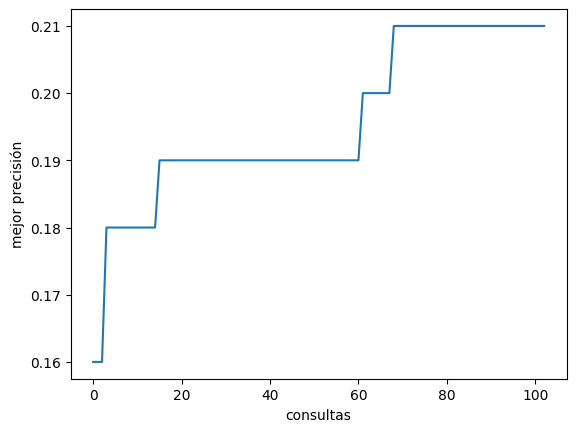

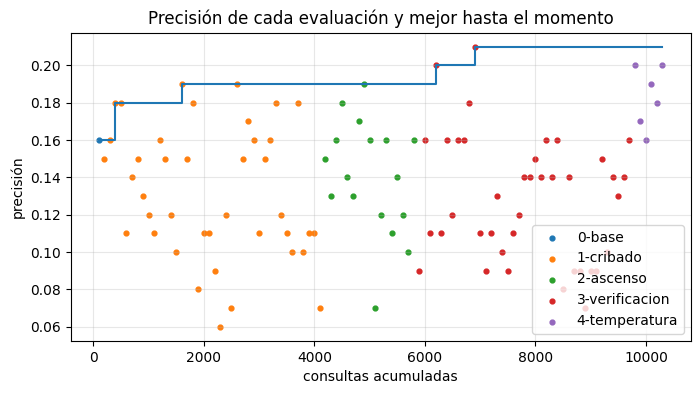

Guardado: registro_busqueda.csv y cribado.csv


In [11]:
import matplotlib.pyplot as plt
from ayudas import curva

df_reg = pd.DataFrame([{**{k: v for k, v in f.items() if k not in ("config", "familias")},
                        **{r: f["config"].get(r, "–") for r in RANURAS},
                        "temperatura": f["config"].get("temperatura"),
                        "familias_mas_violadas": "; ".join(f"{a} ×{b}" for a, b in f["familias"].most_common(3))}
                       for f in reg.filas])
display(df_reg[["n", "fase", *RANURAS, "temperatura", "semilla", "precision", "consultas",
                "generaciones", "segundos", "familias_mas_violadas"]])
print(f"Evaluaciones: {len(reg.filas)} · consultas: {reg.consultas} · "
      f"generaciones nuevas en esta sesión: {reg.generaciones}")
print(f"Fuerza bruta habría necesitado {len(CONFIGS)} × {len(INSTANCIAS)} = {len(CONFIGS)*len(INSTANCIAS):,} consultas")

curva(reg.historial)   # mejor precisión hasta cada consulta (función del curso)

# Mejor precisión contra consultas acumuladas, coloreado por fase
acum, m, xs, ys = 0, 0.0, [], []
for f in reg.filas:
    acum += f["consultas"]; m = max(m, f["precision"]); xs.append(acum); ys.append(m)
plt.figure(figsize=(8, 4))
plt.step(xs, ys, where="post")
for fase in df_reg["fase"].unique():
    sub = df_reg[df_reg["fase"] == fase]
    plt.scatter([xs[i - 1] for i in sub["n"]], sub["precision"], s=12, label=fase)
plt.xlabel("consultas acumuladas"); plt.ylabel("precisión"); plt.legend(); plt.grid(alpha=.3)
plt.title("Precisión de cada evaluación y mejor hasta el momento")
plt.show()

df_reg.to_csv(f"{CARPETA}/registro_busqueda.csv", index=False)
df_reg.to_csv("registro_busqueda.csv", index=False)
df_crib.to_csv("cribado.csv", index=False)
print("Guardado: registro_busqueda.csv y cribado.csv")

## Leer los fallos de la configuración elegida

In [12]:
from collections import Counter
from ayudas import ver_prompt

r = oraculo.evaluar(mejor[1], INSTANCIAS, semilla=1)   # sale del caché
print(r, "\nFamilias que más fallan:")
for fam, v in Counter(t["violo"] for t in r.trazas).most_common(8):
    print(f"  {v:3}  {fam}")
print()
for t in r.trazas[:3]:
    print("violó:", t["violo"]); print(t["salida"][:300]); print("-" * 60)

print("\nPrompt completo de la primera instancia con la config elegida:\n")
print(ver_prompt(mejor[1], INSTANCIAS[0]))

Resultado(precision=21.0%, fallos=79/100) 
Familias que más fallan:
    9  last_word:last_word_sent
    6  copy:copy
    5  new:copy_span_idx
    4  keywords:keyword_specific_position
    4  detectable_format:sentence_hyphens
    4  copy:repeat_phrase
    3  punctuation:punctuation_dot
    3  startend:quotation

violó: letters:letter_counting2
<<answer>>  
The letter o should appear less than 9 times.  
My answer will cover the background context of the question and provide a response with an emphatic adverb in every sentence.  
The background context is that the question asks about the best place to go for a vacation.  
The emphatic adve
------------------------------------------------------------
violó: punctuation:punctuation_dot
The function will analyze the progress of a list of projects and provide a summary report based on the given criteria. It will calculate the average completion percentage, the average completion percentage of high priority projects, and the count of project

## Validación final con `oraculo.validar`
Las 87 instancias de validación no se usaron al buscar. Mide si la configuración aguanta instancias
nuevas de las mismas familias; no es la nota: la profesora evalúa sobre un test privado con familias
que no están en este archivo. No se usa para elegir otra configuración.

In [13]:
r_val = oraculo.validar(mejor[1], n=None)    # n=None → las 87
print("\nbúsqueda (elegida):", f"{mejor[0]:.1%}")
print("validación:        ", f"{r_val.precision:.1%}")

validando:   0%|          | 0/87 [00:00<?, ?inst/s]

validación: 18.4%  (87 inst)
    6  last_word:last_word_sent
    5  copy:repeat_phrase
    5  punctuation:punctuation_dot
    4  letters:letter_counting
    4  length_constraints:nth_paragraph_first_word
    4  keywords:no_adjacent_consecutive
    3  detectable_format:multiple_sections
    3  new:copy_span_idx

búsqueda (elegida): 21.0%
validación:         18.4%


#### Interpretación de la validación
- 18,4 % (16 de 87) en validación frente a 21 % en búsqueda: baja 2,6 puntos. Con 87 instancias el error estándar es ≈ ±4,2 puntos, así que la diferencia está dentro del ruido: la configuración se sostiene en instancias nuevas de las mismas familias.
- Las familias que más fallan (`last_word:last_word_sent`, `copy:repeat_phrase`, `punctuation:punctuation_dot`) son las mismas que dominaban en búsqueda: no aparece un tipo de error nuevo.
- La validación no se usó para elegir la configuración.
- No es la nota. La profesora evalúa sobre un test privado con familias que no están en este archivo. Además, si esos datos no traen el campo `restriccion`, el `cierre 3` (que repite las restricciones) no agrega texto y su ventaja puede desaparecer.

## Resumen de resultados

| | |
|---|---|
| Configuración elegida | `rol 6 · estrategia 6 · formato 0 · estilo 7 · cierre 3 · temperatura 0.0` |
| Precisión en búsqueda (100 inst.) | 21 % (base sin instrucciones: 16 %) |
| Precisión en validación (87 inst.) | 18,4 % |
| Garantía | Óptimo local 1-opt verificado (35 vecinos evaluados). No es un óptimo global probado: el problema es NP-difícil |
| Costo | 103 evaluaciones · 10 300 consultas, frente a 3 276 800 de la fuerza bruta (0,31 %) |
| Tiempo por evaluación (T4) | ≈ 180–220 s; total ≈ 5–6 h de GPU repartidas en varias sesiones gracias al caché |

## La entrega

In [14]:
from ayudas import entrega
from google.colab import files
import shutil

entrega(grupo="G01", config=config_completa(mejor[1]), semana=4)
shutil.copy("entrega.json", f"{CARPETA}/entrega.json")
for f in ["entrega.json", "registro_busqueda.csv", "cribado.csv"]:
    files.download(f)

{
 "grupo": "G01",
 "config": {
  "rol": 6,
  "estrategia": 6,
  "formato": 0,
  "estilo": 7,
  "cierre": 3,
  "temperatura": 0.0
 },
 "semana": 4
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## (Opcional) Comparación: búsqueda aleatoria con el mismo número de evaluaciones
Sirve para mostrar que el método supera al azar con el mismo gasto. Cuesta tanto como la búsqueda
entera, así que está apagada por defecto. Usa un registro aparte para no mezclar las tablas.

In [15]:
CORRER_ALEATORIA = False
if CORRER_ALEATORIA:
    from busqueda import busqueda_aleatoria
    reg_azar = Registro(oraculo, INSTANCIAS, semilla=1)
    p_azar, c_azar = busqueda_aleatoria(reg_azar, CONFIGS, evaluaciones=len(reg.filas), semilla_rng=0)
    print(f"Aleatoria ({len(reg_azar.filas)} evals): {p_azar:.1%} {c_azar}")
    print(f"Método G01 ({len(reg.filas)} evals): {mejor[0]:.1%} {mejor[1]}")
    pd.DataFrame([{**f["config"], "precision": f["precision"]} for f in reg_azar.filas]) \
      .to_csv("registro_aleatoria.csv", index=False)